<a href="https://colab.research.google.com/github/317745/IA_PROJECT/blob/main/reid/reid_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [ ]:
import torchvision.models as models
import torchvision.transforms as transform

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
!pip install torchinfo
from torchinfo import summary

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import pathlib
from tqdm import tqdm
import os
from collections import Counter

In [ ]:
from PIL import Image

In [ ]:
from math import ceil

**CARGA Y DESCOMPRESIÓN DE LAS IMAGENES UBICADAS EN LA CARPETA /data EN DRIVE**

In [ ]:
#!cp -r /content/drive/MyDrive/REID/data/resized_images /content/
#!unzip -q /content/drive/MyDrive/REID/data/resized_images.zip -d /content/drive/MyDrive/REID/data/resized_images/

**LISTADO DE LAS IMAGENES**

In [ ]:
def list_files_resized(path, dict_images=None):
    if dict_images is None:
        dict_images = {
            "file_path": [],
            "dir_name": [],
            "file_name": []
        }

    base_path = pathlib.Path(path)

    for entry in os.scandir(base_path):
        entry_path = pathlib.Path(entry.path)

        if entry.is_file():
            if not entry.name.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            actual_dir = entry_path.parent.name.split('_')[0]
            file_name = entry_path.stem

            dict_images["file_path"].append(entry_path.as_posix())
            dict_images["dir_name"].append(actual_dir)
            dict_images["file_name"].append(file_name)


        elif entry.is_dir():
            dict_images = list_files_resized(entry_path, dict_images)

    return dict_images

In [ ]:
#LISTADO DE LAS IMAGENES RECORTADAS Y REDIMENSIONADAS.
df_reid_cat_resized = pd.DataFrame(list_files_resized('./drive/MyDrive/REID/data/resized_images'))

In [ ]:
df_reid_cat_resized.head()

,file_path,dir_name,file_name
0,drive/MyDrive/REID/data/resized_images/1/0001_...,1,0001_007
1,drive/MyDrive/REID/data/resized_images/1/0001_...,1,0001_000
2,drive/MyDrive/REID/data/resized_images/1/0001_...,1,0001_008
3,drive/MyDrive/REID/data/resized_images/1/0001_...,1,0001_009
4,drive/MyDrive/REID/data/resized_images/1/0001_...,1,0001_001


In [ ]:
len(df_reid_cat_resized)

10558

**SPLIT DE IDS PARA ENTRENAMIENTO**

In [ ]:
#EXTRACCION DE LOS IDS DE INDIVIDUO.
ids_unicos = df_reid_cat_resized['dir_name'].unique()

#PARTICION DE IDS EN TRAIN Y TEST.
train, test = train_test_split(ids_unicos, test_size=0.2, random_state=4)

#PARTICION DE LOS DATOS DEL DATASET POR ID INDIVIDUO (col dir_name).
df_train = df_reid_cat_resized[df_reid_cat_resized['dir_name'].isin(train)]
df_test = df_reid_cat_resized[df_reid_cat_resized['dir_name'].isin(test)]

In [ ]:
#EXTRACCIÓN DE LOS IDS DE INDIVIDIO DE LA PARTICION DE ENTRENAMIENTO.
ids_unicos_split_val = df_train['dir_name'].unique()

#PARTICION DE IDS EN TRAIN Y VALIDATION.
train_1, val = train_test_split(ids_unicos_split_val, test_size=0.15, random_state=4)

#PARTICION DE LOS DATOS DEL DATASET POR ID INDIVIDUO (col dir_name).
df_train_1 = df_train[df_train['dir_name'].isin(train_1)]
df_val = df_train[df_train['dir_name'].isin(val)]

In [ ]:
#GUARDADO DE DATASET TRAIN.
df_train_1.to_csv(
    "./drive/MyDrive/REID/data/csv/train.csv", index=False
)

In [ ]:
print(f'Filas totales de entrenamiento: {len(df_train_1)}')

Filas totales de entrenamiento: 7346


In [ ]:
#GUARDADO DE DATASET VALIDATION.
df_val.to_csv(
    "./drive/MyDrive/REID/data/csv/val.csv", index=False
)

In [ ]:
print(f'Filas totales de validación: {len(df_val)}')

Filas totales de validación: 1135


In [ ]:
#GUARDADO DE DATASET TEST.
df_test.to_csv(
    "./drive/MyDrive/REID/data/csv/test.csv", index=False
)

In [ ]:
print(f'Filas totales de testeo: {len(df_test)}')

Filas totales de testeo: 2077


**FORMACIÓN DE LAS TRIPLETAS**

**CONJUNTO DE 3 IMAGENES: ANCLA, POSITIVA Y NEGATIVA**

**ANCLA: IMAGEN DEL INDIVIDUO DE INTERES**

**POSITIVA: IMAGEN DEL INDIVIDUO DE INTERES EN OTRA POSICIÓN**

**NEGATIVA: IMAGEN DE UN INDIVIDUO DISTINTO**


In [ ]:
def make_tripletas(df):
    dict_tripletas = {
        'id_positives': [],
        'id_negatives': [],
        'path_anchors': [],
        'path_positives': [],
        'path_negatives': []
    }
    ids = sorted(df['dir_name'].unique())

    #FROMACION DE LAS TRIPLETAS EN CADA UNO DE LOS IDS.
    for id_positive in ids:
        list_images = df.loc[df['dir_name'] == id_positive, 'file_path'].tolist()
        total_images = len(list_images)

        if total_images < 2:
          continue

        negatives = df[df['dir_name'] != id_positive]
        half_images = total_images//2

        for j in range(half_images + 1):
            if j != half_images:
                path_anchor = list_images[j]
                path_positive = list_images[j + half_images]

            elif total_images % 2 != 0:
                path_anchor = list_images[j]
                path_positive = list_images[-1]
            else:
              continue

            #EXTRACCIÓN DE LA IMAGEN NEGATIVA.
            negative_row = negatives.sample(n=1).iloc[0]
            id_negative = negative_row['dir_name']
            path_negative = negative_row['file_path']

            dict_tripletas['id_positives'].append(id_positive)
            dict_tripletas['id_negatives'].append(id_negative)
            dict_tripletas['path_anchors'].append(path_anchor)
            dict_tripletas['path_positives'].append(path_positive)
            dict_tripletas['path_negatives'].append(path_negative)

    return dict_tripletas

In [ ]:
#FORMACIÓN DE LAS TRIPLETAS PARA VALIDACIÓN.
dict_tripletas_val = make_tripletas(df_val)

#FORMACIÓN DEL DATASET DE LAS TRIPLETAS PARA VALIDACIÓN.
df_tripletas_val = pd.DataFrame(dict_tripletas_val)
df_tripletas_val.to_csv(
    "./drive/MyDrive/REID/data/csv/tripletas_val.csv", index=False
)

#FORMACIÓN DE LAS TRIPLETAS PARA ENTRENAMIENTO.
dict_tripletas_train = make_tripletas(df_train_1)

#FORMACIÓN DEL DATASET DE LAS TRIPLETAS PARA ENTRENAMIENTO.
df_tripletas_train = pd.DataFrame(dict_tripletas_train)

In [ ]:
print(f'La cantidad de tripletas formadas para entrenamiento fue de: {len(df_tripletas_train)}')

La cantidad de tripletas formadas para entrenamiento fue de: 3746


In [ ]:
print(f'La cantidad de tripletas formadas para validacion fue de: {len(df_tripletas_val)}')

La cantidad de tripletas formadas para validacion fue de: 582


In [ ]:
#TRANFORMACIONES DE LAS IMAGENES
transformaciones = transform.Compose([
    #IMAGENES A TENSORES
    transform.ToTensor(),
    #NORMALIZACIÓN DE LAS IMAGENES POR CANAL
    transform.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
    ])

**FOORMACIÓN DEL DATASET DE ENTRENAMIENTO Y VALIDACIÓN FORMA DE CLASE EN TORCH**

In [ ]:
class ReidCatsDatasetTrain(Dataset):
    def __init__(self, df, transform=None):
        self.annotations = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        anchor = Image.open(self.annotations.iloc[index, 2]).convert('RGB')
        positive = Image.open(self.annotations.iloc[index, 3]).convert('RGB')
        negative = Image.open(self.annotations.iloc[index, 4]).convert('RGB')

        if self.transform:
            anchor = self.transform(anchor)
            positive = self.transform(positive)
            negative = self.transform(negative)

        return anchor, positive, negative

In [ ]:
#RUTA DEL CSV TRIPLETAS TRAIN
path_csv_train = "./drive/MyDrive/REID/data/csv/tripletas.csv"

#CARGA DEL DATASET DE ENTRENAMIENTO PARA TORCH
df_train_class = ReidCatsDatasetTrain(
    df=df_tripletas_train,
    transform = transformaciones
    )

In [ ]:
#RUTA DEL CSV TRIPLETAS TRAIN
path_csv_val = "./drive/MyDrive/REID/data/csv/tripletas_val.csv"

df_val_class = ReidCatsDatasetTrain(
    df=df_tripletas_val,
    transform = transformaciones
    )

#DATALOADER DATASET, TOMA CADA FOTO Y LA CARGA EN LOTES DE 16 FOTOS
#DE MANERA ORDENADA LISTAS PARA EL MODELO
dataloader_val = DataLoader(
    dataset=df_val_class,
    batch_size=16, shuffle=False,
    num_workers=0)

In [ ]:
#SELECCIONAR EL TIPO DE UNIDAD DE PROCESAMIENTO (GPU PREDETERMINADO)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
print(f"Device: {device}")

Device: cuda


#**RESNET 18** (FINE TUNNING)

In [ ]:
#CARGA DEL MODELO ResNet18 CON SUS PESOS PREENTRENADOR EN ImageNet
model_1 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


In [ ]:
#SALIDAS DE CADA UNA DE LAS CAPAS DEL MODELO, CON TAMAÑO DE IMAGEN
#BATCH Y CANALES
summary(model_1, input_size=(16, 3, 300, 300))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [16, 1000]                --
├─Conv2d: 1-1                            [16, 64, 150, 150]        9,408
├─BatchNorm2d: 1-2                       [16, 64, 150, 150]        128
├─ReLU: 1-3                              [16, 64, 150, 150]        --
├─MaxPool2d: 1-4                         [16, 64, 75, 75]          --
├─Sequential: 1-5                        [16, 64, 75, 75]          --
│    └─BasicBlock: 2-1                   [16, 64, 75, 75]          --
│    │    └─Conv2d: 3-1                  [16, 64, 75, 75]          36,864
│    │    └─BatchNorm2d: 3-2             [16, 64, 75, 75]          128
│    │    └─ReLU: 3-3                    [16, 64, 75, 75]          --
│    │    └─Conv2d: 3-4                  [16, 64, 75, 75]          36,864
│    │    └─BatchNorm2d: 3-5             [16, 64, 75, 75]          128
│    │    └─ReLU: 3-6                    [16, 64, 75, 75]          --
│

In [ ]:
#REEMPLAZO DE LA ULTIMA CAPA FC, POR UNA SALIDA DE 512
model_1.fc = nn.Linear(model_1.fc.in_features, 512)

#USAR LA UNIDAD DE PROCESAMIENTO PARA EL MODELO
model_1 = model_1.to(device)

#CARGA DE LA FUNCION DE PERDIDA TRIPLET MARGIN LOSS
#CON UN MARGEN DE DISTANCIA MINIMA DE 0.5
triplet_loss_fn = nn.TripletMarginLoss(margin=0.5, p=2.0)

#OPTIMIZADOR: ADAM
#ACTUALIZA LOS PESOS USANDO LOS GRADIENTES DEL BACKPROPAGATION.
#AJUSTA EL PASO DE CADA PESO DE FORMA INDIVIDUAL.

#MODEL_1.PARAMETERS(): TODOS LOS PESOS DE LA RED SE ACTUALIZAN.

#LR=0.0001: BAJO A PROPÓSITO, PORQUE LA RED YA VIENE PREENTRENADA Y
#SE QUIERE AJUSTAR CON CUIDADO.
optimizer_model_1 = optim.Adam(model_1.parameters(), lr=0.0001)

In [ ]:
#EXTRACCIÓN DEL EMBEDDING
#PASA UN LOTE DE IMÁGENES POR RESNET-18
#OBTIENE UN VECTOR DE 512 NÚMEROS POR IMAGEN.

#F.normalize(..., p=2, dim=1) DIVIDE CADA VECTOR ENTRE SU NORMA L2, ASÍ
#TODOS LOS EMBEDDINGS QUEDAN CON LONGITUD 1, ASÍ LA DISTANCIA ENTRE DOS
# EMBEDDINGS DEPENDE SOLO DE LA DIRECCIÓN DEL VECTOR.

def get_embeddings(x):
    return F.normalize(model_1(x), p=2, dim=1)

def train_resnet18(epochs = 10, save_path="mejor_modelo.pth"):

    #ACUMULACIÓN DE LAS PERDIDAS POR EPOCA EN TRAIN Y VALIDATION.
    train_losses, val_losses = [], []

    #SE ESTABLECE UN VALOR INFINITO, PARA QUE NO SE GUARDE EL MODELO
    #EN LA PRIMERA EPOCA.
    best_val = float('inf')

    #ITERACIÓN POR EPOCAS
    for epoch in tqdm(range(epochs)):
        df_tripletas_epoch = pd.DataFrame(make_tripletas(df_train_1))
        dataloader_train = DataLoader(
            ReidCatsDatasetTrain(df=df_tripletas_epoch, transform=transformaciones),
            batch_size=16, shuffle=True, num_workers=2
        )
        #ALISTAR EL MODELO PARA SER ENTRENADO.
        model_1.train()
        running = 0.0

        #CICLO DE ENTRENAMIENTO (A UNA ÉPOCA)
        #EL DATALOADER ENTREGA LOTES DE TRIPLETAS: 16 ANCLAS, 16 POSITIVAS
        #Y 16 NEGATIVAS.
        for anchor, positive, negative in dataloader_train:

            #SE JUNTAN LAS 3 IMAGENES EN UN SOLO LOTE DE 48 IMÁGENES
            #Y SE PASAN POR EL MODELO UNA SOLA VEZ.
            batch = torch.cat([anchor, positive, negative]).to(device)

            #SE CALCULAN LOS EMBEDDINGS Y SE SEPARAN DE NUEVO EN 3 GRUPOS DE 16
            #ANCLA, POSITIVA Y NEGATIVA.
            a_emb, p_emb, n_emb = get_embeddings(batch).chunk(3)

            #TRIPLET LOSS: PENALIZA SI LA ANCLA NO ESTÁ MÁS CERCA DE LA POSITIVA
            #QUE DE LA NEGATIVA POR AL MENOS EL MARGEN (0.5).
            loss = triplet_loss_fn(a_emb, p_emb, n_emb)

            #SE BORRAN LOS GRADIENTES DEL LOTE ANTERIOR.
            optimizer_model_1.zero_grad()

            #BACKPROPAGATION.
            loss.backward()

            #ADAM ACTUALIZA LOS PESOS USANDO LOS GRADIENTES.
            optimizer_model_1.step()

            #SE ACUMULA LA PÉRDIDA DEL LOTE.
            running += loss.item()

        #PÉRDIDA PROMEDIO DE LA ÉPOCA.
        train_loss = running / len(dataloader_train)

        #ALISTAR EL MODELO PARA SER EVALUADO.
        model_1.eval()
        running = 0.0
        with torch.no_grad():
            for anchor, positive, negative in dataloader_val:
                batch = torch.cat([anchor, positive, negative]).to(device)
                a_emb, p_emb, n_emb = get_embeddings(batch).chunk(3)
                running += triplet_loss_fn(a_emb, p_emb, n_emb).item()
        val_loss = running / len(dataloader_val)

        #ACUMULACIÓN DE LAS PERDIDAD PROMEDIO POR EPOCAS.
        val_losses.append(val_loss)
        train_losses.append(train_loss)
        print(f"Época {epoch+1}/{epochs} - train: {train_loss:.4f} - val: {val_loss:.4f}")

        #GUARDADO DINAMICO, LA PRESENCIA DE UN MINIMO ACTIVA EL GUARDADO.
        if val_loss < best_val:
            best_val = val_loss
            torch.save(model_1.state_dict(), save_path)

    return train_losses, val_losses

In [ ]:
#ENTRENAMIENTO DEL MODELO.
train_losses_rn18ft, val_losses_rn18ft = train_resnet18()

 10%|█         | 1/10 [26:40<4:00:03, 1600.43s/it]

Época 1/10 - train: 0.0462 - val: 0.0446


 20%|██        | 2/10 [28:21<1:35:47, 718.46s/it] 

Época 2/10 - train: 0.0195 - val: 0.0415


 30%|███       | 3/10 [30:02<50:55, 436.56s/it]  

Época 3/10 - train: 0.0170 - val: 0.0419


... (10 outputs left out)

 90%|█████████ | 9/10 [40:12<02:08, 128.46s/it]

Época 9/10 - train: 0.0098 - val: 0.0334


100%|██████████| 10/10 [41:53<00:00, 251.37s/it]

Época 10/10 - train: 0.0077 - val: 0.0305


In [ ]:
#GUARDADO DEL MODELO EN EL DRIVE.
!cp mejor_modelo.pth /content/drive/MyDrive/REID/MODELOS

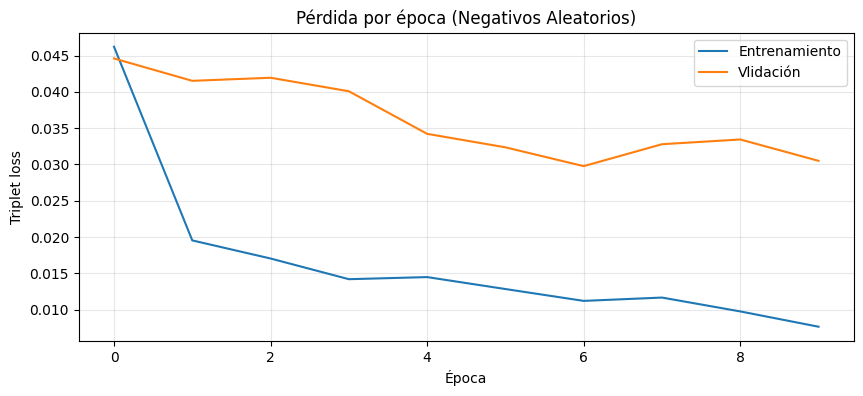

In [ ]:
#GRAFICA DE LAS PERDIDAS POR EPOCA (VALIDACIÓN Y ENTRENAMIENTO).
plt.figure(figsize=(10, 4))
plt.plot(train_losses_rn18ft, label='Entrenamiento')
plt.plot(val_losses_rn18ft, label='Vlidación')
plt.xlabel("Época")
plt.ylabel("Triplet loss")
plt.title("Pérdida por época (Negativos Aleatorios)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**TEST MODEL**

In [ ]:
#CARGA DEL MODELO USANDO LA UNIDAD DE PROCESAMIENTO ESTABLECIDA.
model_1.load_state_dict(torch.load("/content/drive/MyDrive/REID/MODELOS/mejor_modelo.pth", map_location=device))

<All keys matched successfully>

In [ ]:
#CARGA DEL DATASET DE VALIDACIÓN COMO CLASE PARA TORCH
class ReidCatsDatasetTest(Dataset):
    def __init__(self, csv_file, transform=None):
        self.annotations = pd.read_csv(csv_file)
        self.transform = transform

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        path_image = self.annotations.loc[index, 'file_path']
        image = Image.open(path_image).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image

In [ ]:
#EXTRACCIÓN DE EMBEDDINGS DEL CONJUNTO DE PRUEBA.
#@torch.no_grad(): EN EVALUACIÓN NO SE ENTRENA, ASÍ QUE NO SE GUARDAN.
@torch.no_grad()
def eval_model_1(path_csv):

  #MODO EVALUACIÓN DEL MODELO.
  model_1.eval()

  df_test = ReidCatsDatasetTest(
      csv_file=path_csv,
      transform=transformaciones
  )

  df_test_loader = DataLoader(
        dataset = df_test,
        batch_size=16,
        shuffle=False,
        #num_workers=2: DOS PROCESOS CARGAN IMÁGENES EN PARALELO.
        num_workers=2
  )

  #GUARDADO DE LOS EMBEDDINGS POR LOTE.
  embeds = []
  for cat in tqdm(df_test_loader):
    cat = cat.to(device)
    embeds_by_batch = get_embeddings(cat)
    embeds.append(embeds_by_batch)

  #SE UNEN TODOS LOS LOTES UNA SOLA VEZ AL FINAL:
  embeds = torch.cat(embeds)

  return embeds

In [ ]:
#EVALUACIÓN DEL MODELO CON EL DATASETS DE TEST.
model_1_embeds = eval_model_1("./drive/MyDrive/REID/data/csv/test.csv")

100%|██████████| 130/130 [06:13<00:00,  2.87s/it]


**PARA EL CALCULO DE LAS METRICAS DE UN MODELO DE REID ES FUNDAMENTAL**

**ASIGNARO ROLES A LOS DATOS EN GALERIA (Gallery) y Consultar (Querys)**

In [ ]:
def make_split(df, n_query=2):
  df = df.copy()

  #EXTRACCIÓN DE LOS IDS DE TESTING PARA TESTING
  ids = df['dir_name'].unique()

  #CREACIÓN DE LA COL rol ENCARGADA DE ASIGNAR ROLES
  #A LOS DATOS (gallery or query)
  df['rol'] = 'gallery'
  rng = np.random.default_rng(4)

  #DE CADA INDIVIDUO LA IDEA PRINCIPAL ES TOMAR MINIMO UNA MUESTRA Y MAXIMO 2
  #DESCARTA LOS INDIVIDUOS CON MINIMO UN SOLO REGISTRO.
  for cat_id in ids:
    filas = df.index[df['dir_name'] == cat_id]
    if len(filas) == 1:
      continue

    #SELECCIONAR LA CANTIDAD DE querys MINIMAS POSIBLES.
    n = min(n_query, len(filas) - 1)
    elegidas = rng.choice(filas, size=n, replace=False)

    #ESTABLECER EL ROL DE LA IMAGEN.
    df.loc[elegidas, 'rol'] = 'query'

  return df

In [ ]:
#REALIZAR LA PARTICION DE LOS DATOS SEGUN DISPONIBILIDAD DE IMAGENES.
df_split_images = make_split(df_test)

#SUBIDA DEL DATASET DE PARTICIÓN.
df_split_images.to_csv(
    './drive/MyDrive/REID/data/csv/df_split_gallery.csv', index=False
)

In [ ]:
total_gallery_images = (df_split_images['rol'] == 'gallery').sum()
total_query_images = (df_split_images['rol'] == 'query').sum()

In [ ]:
print(f'Total de registros gallery: {total_gallery_images}')

Total de registros gallery: 1883


In [ ]:
print(f'Total de registros gallery: {total_query_images}')

Total de registros gallery: 194


**SEPARA CONSULTAS Y GALERÍA Y CALCULA LA MATRIZ DE DISTANCIAS ENTRE ELLAS.**

In [ ]:
def test_model_1(df, embeds):
  df_split = df.reset_index(drop=True)
  df_split['dir_name'] = df_split['dir_name'].astype(int)

  #ID DEL GATO DE CADA CONSULTA Y DE CADA FOTO DE GALERÍA.
  ids_q = torch.as_tensor(df_split[df_split['rol'] == 'query']['dir_name'].to_numpy())
  ids_g = torch.as_tensor(df_split[df_split['rol'] == 'gallery']['dir_name'].to_numpy())

  #POSICIÓN DE CADA gallery DENTRO DE EMBEDS.
  index_querys = torch.as_tensor(df_split.index[df_split['rol'] == 'query'].to_numpy())
  index_gallery = torch.as_tensor(df_split.index[df_split['rol'] == 'gallery'].to_numpy())

  #SELECCIÓN DE LOS EMBEDDINGS DE CADA GRUPO.
  querys = embeds[index_querys]
  gallery = embeds[index_gallery]

  #MATRIZ (querys x gallery): DISTANCIA DE CADA CONSULTA.
  matrix = torch.cdist(querys, gallery)

  return matrix, ids_q, ids_g

In [ ]:
distances, ids_q, ids_g = test_model_1(df_split_images, model_1_embeds)

**CALCULO DE LAS METRICAS DE TESTING**

**RANK-1, RANK-5, RANK-10 Y mAP (Men Avarage Presition)**

In [ ]:
def metricas_reid(dist, q_ids, g_ids, ks=(1, 5, 10)):
    g_ids = g_ids.to(device)
    q_ids = q_ids.to(device)

    #ORDENA CADA FILA, DE MENOR A MAYOR DISTANCIA.
    orden = torch.argsort(dist, dim=1)

    #CADA FILA QUEDA COMO EL RANKING DE IDS PARA LA query.
    g_ordenados = g_ids[orden]

    #MATRIZ DE ACIERTOS
    #1 SI LA FOTO DEL RANKING ES DEL MISMO GATO QUE LA
    #CONSULTA, 0 SI NO.
    aciertos = (g_ordenados == q_ids.unsqueeze(1)).float()

    #SELECCIONA SOLO LAS PRIMERAS K COLUMNAS DEL RANKING.
    #.MAX(DIM=1) DA 1 SI HAY AL MENOS UN ACIERTO ENTRE LAS K COLS.
    #.MEAN() FRACCIÓN DE CONSULTAS QUE ACERTARON.
    resultados = {}
    for k in ks:
        resultados[f'rank{k}'] = aciertos[:, :k].max(dim=1).values.mean().item()

    #SUMA LOS ACIERTOS POR FILA.
    acumulado = aciertos.cumsum(dim=1)

    #CALCULO DE LA PRESICIÓN EN CADA PUESTO
    posiciones = torch.arange(1, aciertos.shape[1] + 1, device=aciertos.device)
    precision = acumulado / posiciones

    #SUMA DE LOS ACIERTOS TOTALES.
    n_relevantes = aciertos.sum(dim=1)

    #PRESICIÓN PROMEDIO POR CADA CONSULTA.
    ap = (precision * aciertos).sum(dim=1) / n_relevantes.clamp(min=1)

    #CALCULO DEL PROMEDIO DE AP
    resultados['mAP'] = ap[n_relevantes > 0].mean().item()

    return resultados

In [ ]:
results = metricas_reid(
    dist = distances,
    q_ids = ids_q,
    g_ids = ids_g
)

In [ ]:
results

{'rank1': 0.876288652420044,
 'rank5': 0.9329896569252014,
 'rank10': 0.9536082148551941,
 'mAP': 0.691132128238678}

In [ ]:
df_results = pd.DataFrame(results, index=['resnet-18']).T

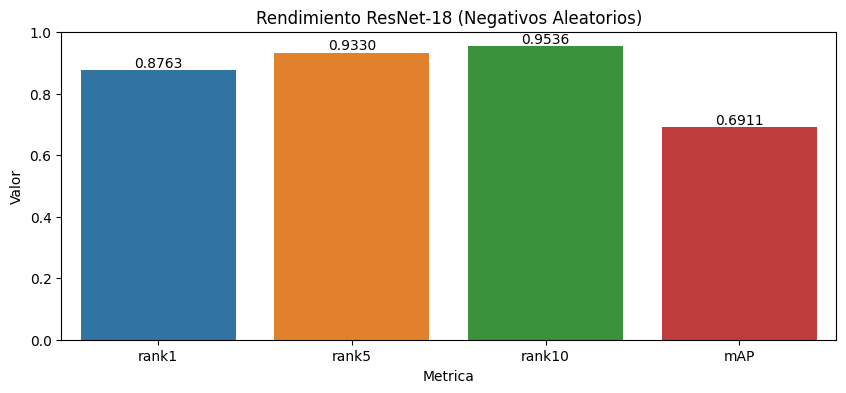

In [ ]:
plt.figure(figsize=(10, 4))
ax = sns.barplot(data=df_results, x=df_results.index, y='resnet-18', hue=df_results.index)
for container in ax.containers:
  ax.bar_label(container, fontsize=10, fmt='%.4f')

plt.title("Rendimiento ResNet-18 (Negativos Aleatorios)")
plt.xlabel("Metrica")
plt.ylabel("Valor")
plt.show()

**MODEL_2: RESNET 18**

In [ ]:
model_2 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_2.fc = nn.Identity()
model_2 = model_2.to(device)

In [ ]:
def get_embeddings_model(x, model):
  return F.normalize(model(x), p=2, dim=1)

#EXTRACCIÓN DE EMBEDDINGS DEL CONJUNTO DE PRUEBA.
@torch.no_grad()
def eval_model(path_csv, model):

  #MODO EVALUACIÓN DEL MODELO.
  model.eval()

  df_test = ReidCatsDatasetTest(
      csv_file=path_csv,
      transform=transformaciones
  )

  df_test_loader = DataLoader(
        dataset = df_test,
        batch_size=16,
        shuffle=False,
        #num_workers=2: DOS PROCESOS CARGAN IMÁGENES EN PARALELO.
        num_workers=2
  )

  #GUARDADO DE LOS EMBEDDINGS POR LOTE.
  embeds = []
  for cat in tqdm(df_test_loader):
    cat = cat.to(device)
    embeds_by_batch = get_embeddings_model(cat, model)
    embeds.append(embeds_by_batch)

  #SE UNEN TODOS LOS LOTES UNA SOLA VEZ AL FINAL:
  embeds = torch.cat(embeds)

  return embeds

In [ ]:
model_2_embeds = eval_model('./drive/MyDrive/REID/data/csv/test.csv', model_2)

100%|██████████| 130/130 [00:08<00:00, 14.80it/s]


In [ ]:
distances_model_2, ids_q_model_2, ids_g_model_2 = test_model_1(df_split_images, model_2_embeds)

In [ ]:
results_model_2 = metricas_reid(
    dist = distances_model_2,
    q_ids = ids_q_model_2,
    g_ids = ids_g_model_2
)

In [ ]:
results_model_2

{'rank1': 0.8814432621002197,
 'rank5': 0.9226803779602051,
 'rank10': 0.9432989358901978,
 'mAP': 0.65188068151474}

In [ ]:
df_results_model_2 = pd.DataFrame(results_model_2, index=['resnet-18']).T

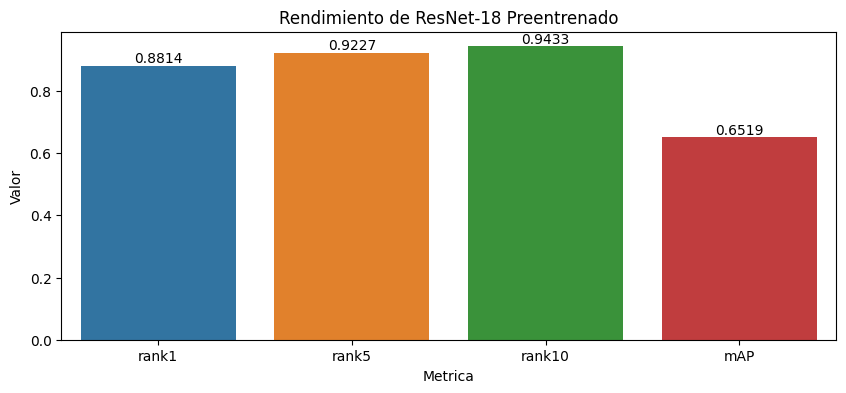

In [ ]:
plt.figure(figsize=(10, 4))
ax = sns.barplot(data=df_results_model_2, x=df_results_model_2.index, y='resnet-18', hue=df_results_model_2.index)
for container in ax.containers:
  ax.bar_label(container, fontsize=10, fmt='%.4f')

plt.title("Rendimiento de ResNet-18 Preentrenado")
plt.xlabel("Metrica")
plt.ylabel("Valor")
plt.show()

**MODELO 3: RESNET-18 FT**

In [ ]:
torch.manual_seed(4)
model_3 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_3.fc = nn.Linear(model_3.fc.in_features, 512)
model_3 = model_3.to(device)

optimizer_model_3 = optim.Adam(model_3.parameters(), lr=0.0001)

dataloader_train_fixed = DataLoader(
    ReidCatsDatasetTrain(
        df=df_tripletas_train,
        transform=transformaciones),
    batch_size=16,
    shuffle=True,
    num_workers=2
)

def train_fixed_negatives(epochs=10, save_path="mejor_modelo_neg_fijos_yolo11m.pth"):
    train_losses, val_losses = [], []
    best_val = float('inf')

    for epoch in tqdm(range(epochs)):
        model_3.train()
        running = 0.0
        for anchor, positive, negative in dataloader_train_fixed:
            batch = torch.cat([anchor, positive, negative]).to(device)
            a_emb, p_emb, n_emb = get_embeddings_model(batch, model_3).chunk(3)
            loss = triplet_loss_fn(a_emb, p_emb, n_emb)

            optimizer_model_3.zero_grad()
            loss.backward()
            optimizer_model_3.step()
            running += loss.item()
        train_loss = running / len(dataloader_train_fixed)

        model_3.eval()
        running = 0.0
        with torch.no_grad():
            for anchor, positive, negative in dataloader_val:
                batch = torch.cat([anchor, positive, negative]).to(device)
                a_emb, p_emb, n_emb = get_embeddings_model(batch, model_3).chunk(3)
                running += triplet_loss_fn(a_emb, p_emb, n_emb).item()
        val_loss = running / len(dataloader_val)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(f"Época {epoch+1}/{epochs} - train: {train_loss:.4f} - val: {val_loss:.4f}")

        if val_loss < best_val:
            best_val = val_loss
            torch.save(model_3.state_dict(), save_path)

    return train_losses, val_losses

train_losses_fix, val_losses_fix = train_fixed_negatives()

 10%|█         | 1/10 [01:45<15:47, 105.27s/it]

Época 1/10 - train: 0.0463 - val: 0.0424


 20%|██        | 2/10 [03:25<13:36, 102.08s/it]

Época 2/10 - train: 0.0081 - val: 0.0337


 30%|███       | 3/10 [05:02<11:40, 100.12s/it]

Época 3/10 - train: 0.0037 - val: 0.0357


... (10 outputs left out)

 90%|█████████ | 9/10 [14:56<01:38, 98.90s/it]

Época 9/10 - train: 0.0020 - val: 0.0283


100%|██████████| 10/10 [16:34<00:00, 99.45s/it]

Época 10/10 - train: 0.0019 - val: 0.0411


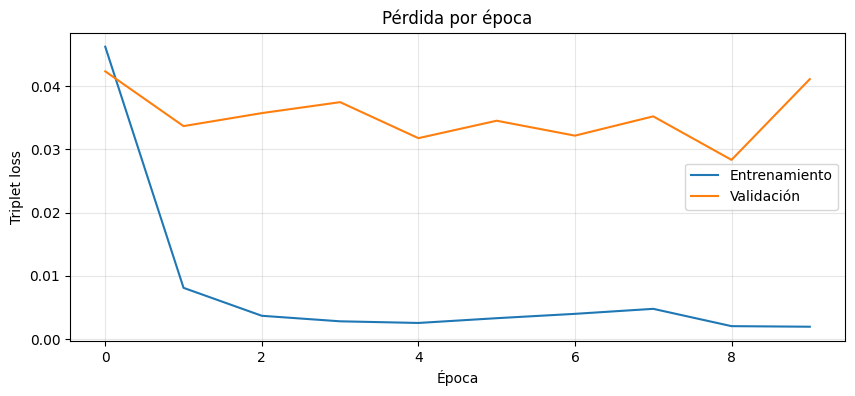

In [ ]:
#GRAFICA DE LAS PERDIDAS POR EPOCA (VALIDACIÓN Y ENTRENAMIENTO).
plt.figure(figsize=(10, 4))
plt.plot(train_losses_fix, label='Entrenamiento')
plt.plot(val_losses_fix, label='Validación')
plt.xlabel("Época")
plt.ylabel("Triplet loss")
plt.title("Pérdida por época")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
model_3.load_state_dict(torch.load("./drive/MyDrive/REID/MODELOS/mejor_modelo_v1.pth", map_location=device))

embeds_3 = eval_model("./drive/MyDrive/REID/data/csv/test.csv", model_3)
d3, q3, g3 = test_model_1(df_split_images, embeds_3)

100%|██████████| 130/130 [00:08<00:00, 15.25it/s]


In [ ]:
results_model_3 = metricas_reid(dist=d3, q_ids=q3, g_ids=g3)
df_results_model_3 = pd.DataFrame(results_model_3, index=['resnet-18']).T

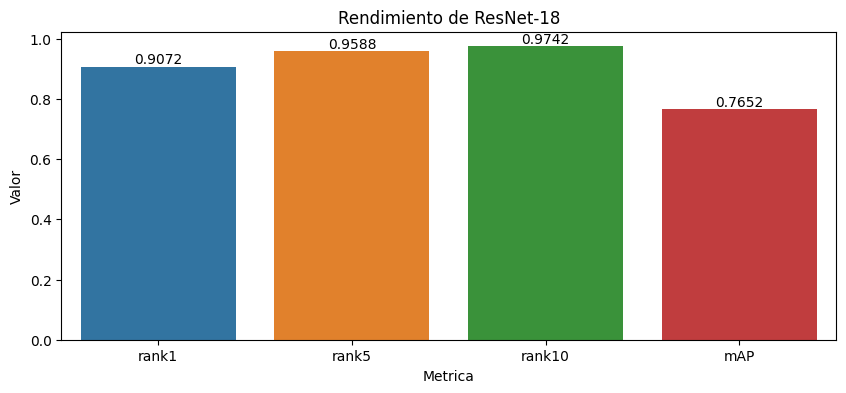

In [ ]:
plt.figure(figsize=(10, 4))
ax = sns.barplot(data=df_results_model_3, x=df_results_model_3.index, y='resnet-18', hue=df_results_model_3.index)
for container in ax.containers:
  ax.bar_label(container, fontsize=10, fmt='%.4f')

plt.title("Rendimiento de ResNet-18")
plt.xlabel("Metrica")
plt.ylabel("Valor")
plt.show()